# Credit Card Fraud Detection Using Machine Learning

## 1. Introduction

Credit card fraud is a major problem in digital financial transactions. Fraudulent transactions can cause financial losses to customers and financial institutions.

The objective of this project is to develop a Machine Learning classification model that identifies whether a credit card transaction is legitimate or fraudulent.

The project uses the Kaggle Playground Series S6E11 dataset.

### Objectives
- Understand and analyze the dataset.
- Perform data preprocessing and feature engineering.
- Train and compare multiple machine learning algorithms.
- Evaluate the models using suitable classification metrics.
- Track experiments using MLflow.
- Save the best-performing model.
- Develop a prediction API and deploy the application.
- 

We import the required Python libraries for data manipulation, visualization, preprocessing, machine learning, evaluation and model saving.

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Feature selection
from sklearn.feature_selection import VarianceThreshold

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Model saving
import joblib

# Other libraries
import os
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


We load the training and testing datasets using Pandas. The training dataset contains the target variable, whereas the testing dataset is used to generate predictions for the Kaggle competition.

In [4]:
# Load datasets
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
sample_submission = pd.read_csv(
    "../data/sample_submission.csv"
)

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)
print("Sample submission:", sample_submission.shape)

Training dataset: (699960, 26)
Testing dataset: (299984, 25)
Sample submission: (299984, 2)


Exploratory Data Analysis helps us understand the structure, features, data types, statistical properties and quality of the dataset before applying machine learning algorithms.

In [6]:
# First five rows
display(train.head())

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [5]:
# Last five rows
display(train.tail())

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
699955,699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,...,3D Secure,POS,Windows PC,False,False,False,False,False,False,0.0
699956,699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,...,No Authentication,Online,iPhone,False,False,False,False,False,False,0.0
699957,699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,...,Biometric,Online,Android Phone,False,False,True,False,False,False,0.0
699958,699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,...,PIN,ATM,Windows PC,False,False,True,False,False,False,0.0
699959,699959,36.16,3.51,3,1.53,48,21,2645.98,0,8.9,...,Biometric,Online,Android Phone,False,False,False,False,False,False,0.0


In [7]:
# Dataset information
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [6]:
# Statistical summary
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,699960.0,NaN,NaN,NaN,349979.5,202061.191549,0.0,174989.75,349979.5,524969.25,699959.0
amount_usd,699960.0,NaN,NaN,NaN,79.893068,205.173538,1.0,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,NaN,NaN,NaN,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,NaN,NaN,NaN,2.984092,1.498998,0.0,2.0,3.0,4.0,11.0
distance_from_home_km,699960.0,NaN,NaN,NaN,13.587575,11.617325,0.0,4.43,10.22,19.75,57.93
card_age_months,699960.0,NaN,NaN,NaN,46.862982,5.57919,25.0,43.0,47.0,51.0,73.0
customer_age,699960.0,NaN,NaN,NaN,51.430286,17.89915,18.0,38.0,52.0,66.0,81.0
account_balance_usd,699960.0,NaN,NaN,NaN,2064.99807,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,NaN,NaN,NaN,0.085472,0.289524,0.0,0.0,0.0,0.0,3.0
velocity_score,699960.0,NaN,NaN,NaN,18.929445,10.864385,0.0,11.4,18.6,26.0,72.9


In [7]:
# Identify numerical and categorical columns
numeric_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'is_fraud']

Categorical columns:
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [8]:
# Identify numerical and categorical columns
numeric_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'is_fraud']

Categorical columns:
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


Missing values can affect machine learning algorithms. We identify missing values in each column and calculate their percentages to decide an appropriate treatment strategy.

In [9]:
missing_analysis = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

display(
    missing_analysis.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
id,0,0.0
amount_usd,0,0.0
hours_since_last_txn,0,0.0
txn_count_last_24h,0,0.0
distance_from_home_km,0,0.0
card_age_months,0,0.0
customer_age,0,0.0
account_balance_usd,0,0.0
cvv_retry_count,0,0.0
velocity_score,0,0.0


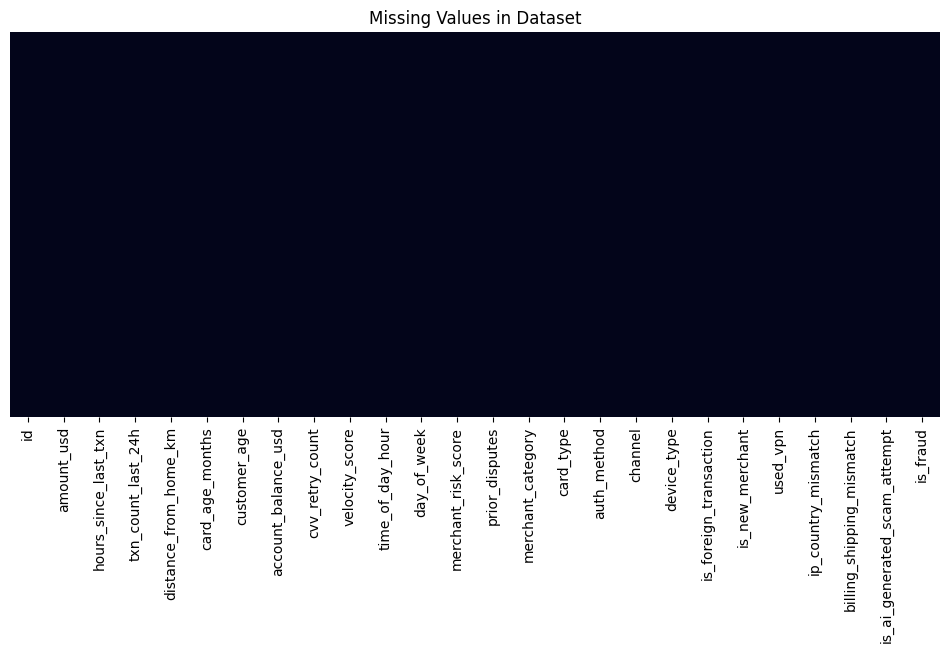

In [10]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    train.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Dataset")
plt.show()

The target variable represents whether a transaction is fraudulent or legitimate. We analyze its distribution to understand the balance between the two classes.

In [10]:
TARGET = "is_fraud"

print(train[TARGET].value_counts())

print("\nPercentage distribution:")
print(train[TARGET].value_counts(normalize=True) * 100)

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

Percentage distribution:
is_fraud
0.0    98.330047
1.0     1.669953
Name: proportion, dtype: float64


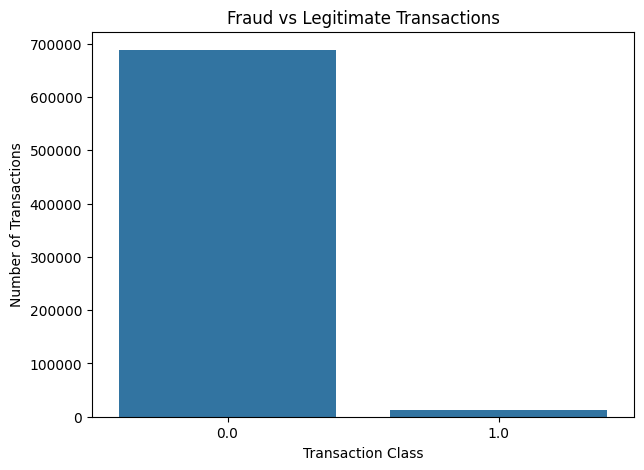

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x=TARGET
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

We visualize numerical features using histograms and boxplots to understand their distributions, identify skewness and investigate possible outliers.

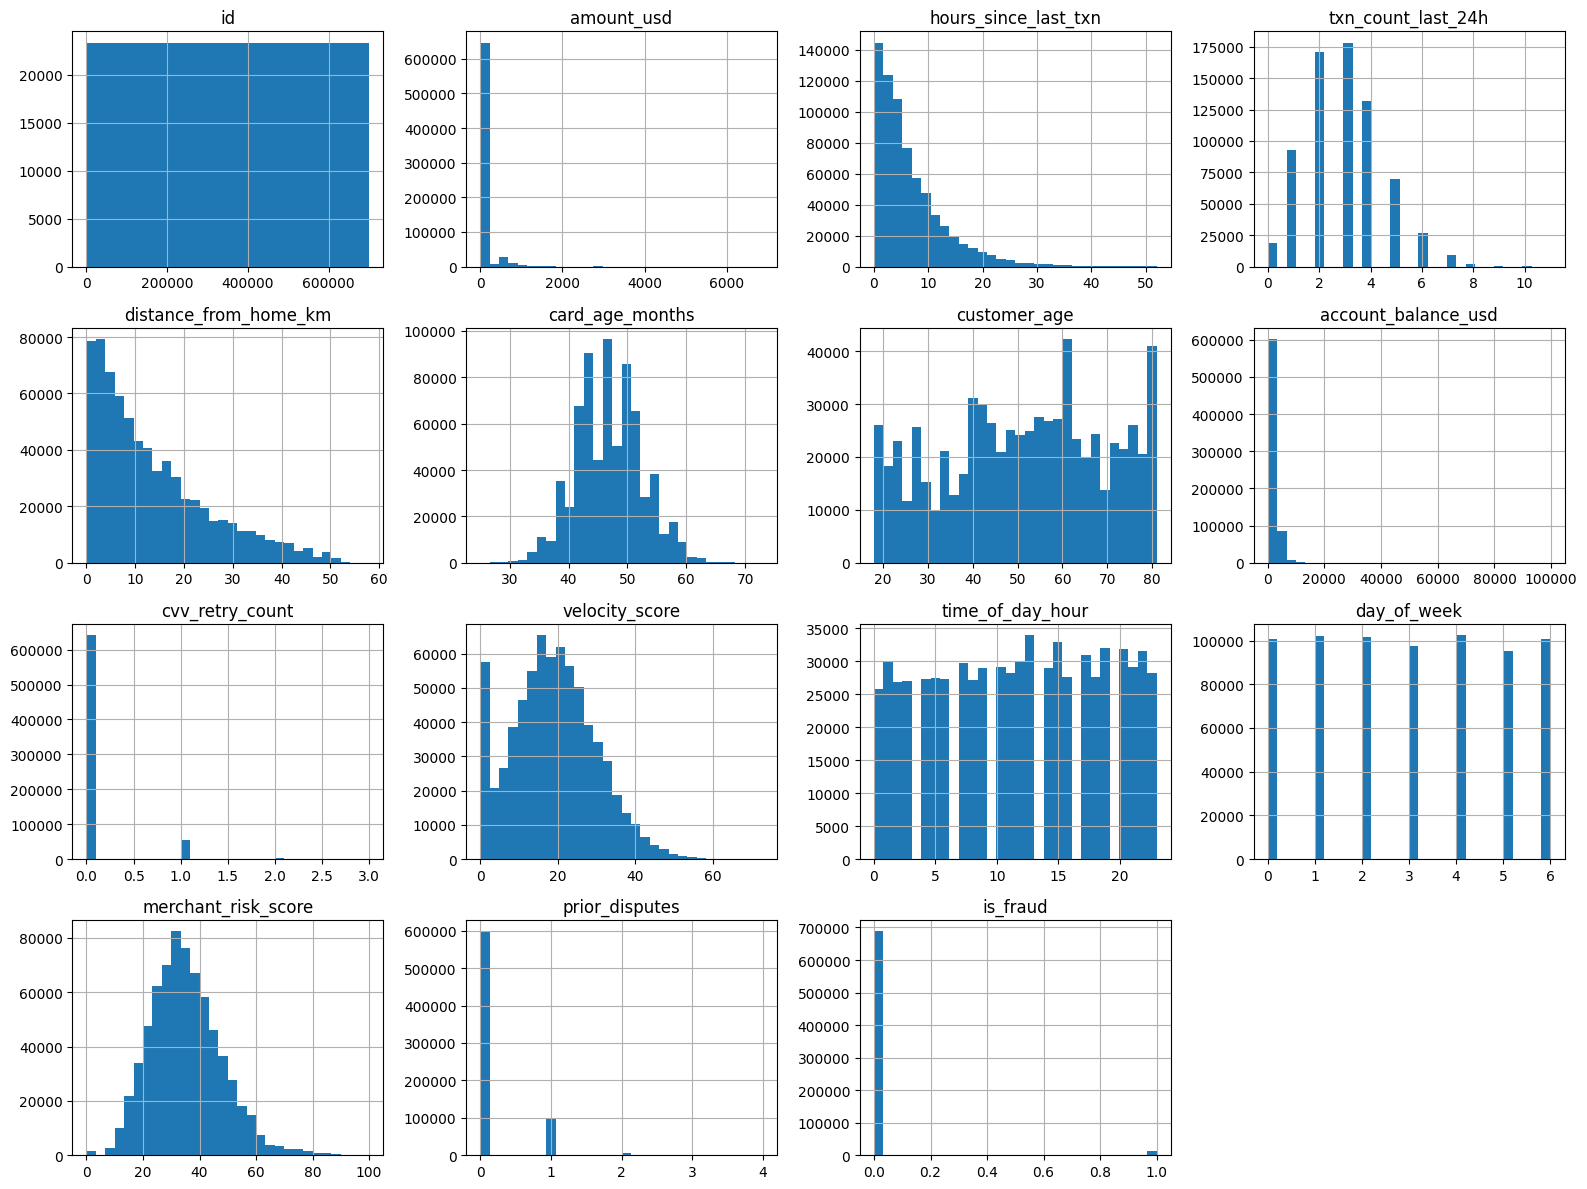

In [12]:
train[numeric_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [ ]:
for col in numeric_columns:
    if col != TARGET:
        plt.figure(figsize=(8, 3))
        sns.boxplot(x=train[col])
        plt.title(f"Boxplot of {col}")
        plt.show()

Correlation analysis helps us understand relationships between numerical features and identify highly correlated variables.

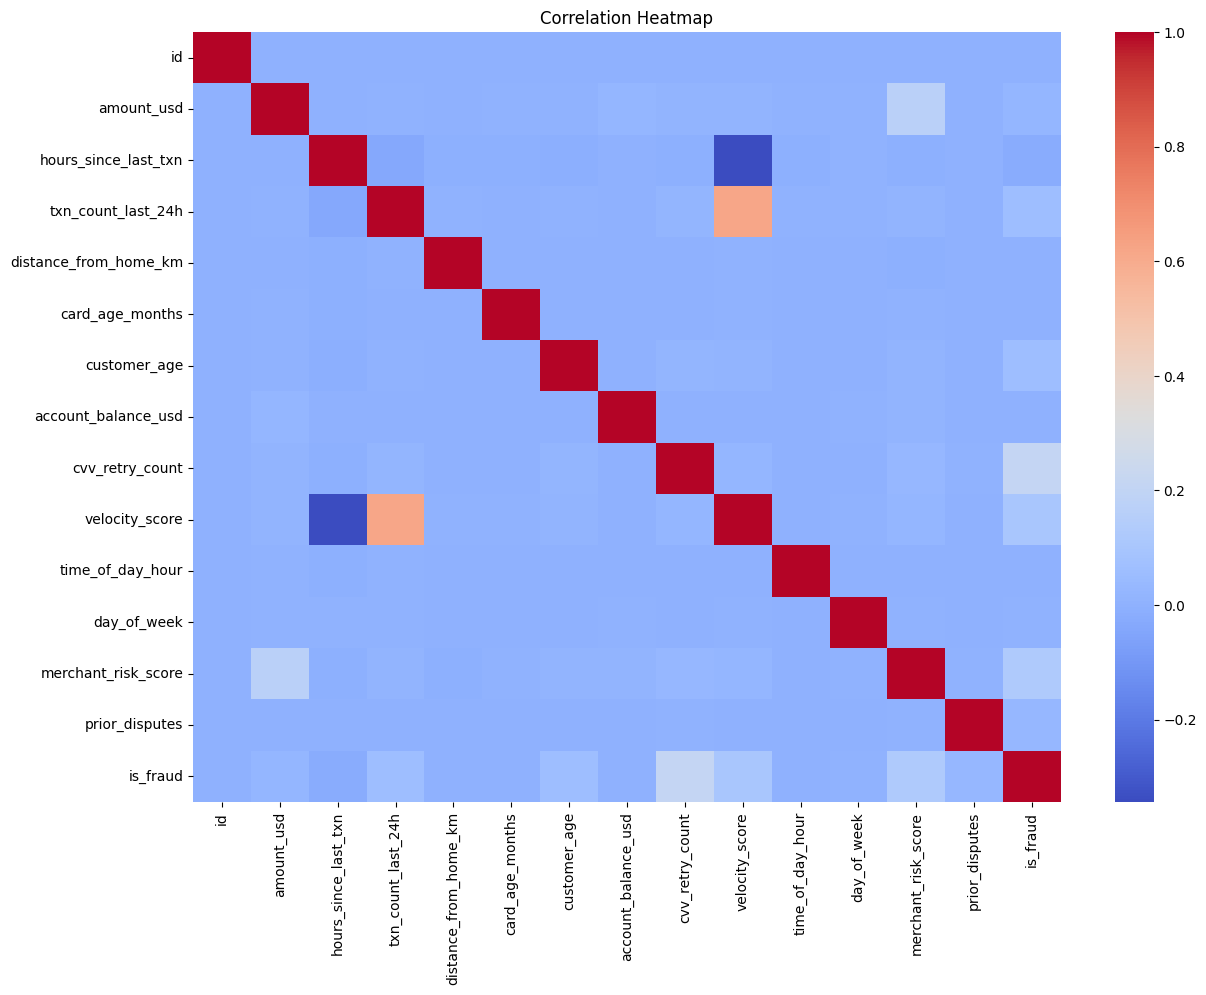

In [14]:
correlation = train[
    numeric_columns
].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap")
plt.show()

Section 9: Train-test split
This must happen before fitting any imputer, encoder or scaler. Your university explicitly warns about data leakage.

In [13]:
TARGET = "is_fraud"

# Separate target and features
X = train.drop(columns=[TARGET])
y = train[TARGET]

# Remove identifier if present
id_column = "id"

if id_column in X.columns:
    X = X.drop(columns=[id_column])

# Split dataset
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (559968, 24)
Validation: (139992, 24)


Section 10: Preprocessing pipeline
We will build separate pipelines for numerical and categorical features.

In [14]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Section 11: Feature selection
We will investigate feature importance and use a suitable feature-selection method.

Our notebook will report:
- Initial number of features.
- Features retained.
- Features removed.
- Reason for selection.
We will avoid removing potentially useful fraud indicators just because they look unusual.

Section 12: Train machine learning models
We will compare at least two algorithms.
Model	Purpose
Logistic Regression	Baseline model
Random Forest	Nonlinear classification
XGBoost	Additional model comparison

Each model will use the same validation split and preprocessing approach.

Section 13: MLflow experiment tracking
We will run at least three experiments using MLflow.

In [ ]:
pip install mlflow

In [15]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\shubh\AppData\Local\Programs\Python\Python313\python.exe

Python version:
3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [16]:
import sys

!{sys.executable} -m pip install mlflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\shubh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [17]:
import mlflow

print("MLflow installed successfully!")
print("Version:", mlflow.__version__)

MLflow installed successfully!
Version: 3.18.0


In [17]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment(
    "Credit_Card_Fraud_Detection"
)

<Experiment: artifact_location='file:C:/Users/shubh/OneDrive/Desktop/Credit-Card-Fraud-Detection/notebooks/mlruns/1', creation_time=1794213825616, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794213825616, lifecycle_stage='active', name='Credit_Card_Fraud_Detection', tags={}, trace_location=None, workspace='default'>

Section 14: Model evaluation
Compare:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
The primary Kaggle metric is ROC-AUC.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

best_model = None
best_score = -1

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("feature_selection", VarianceThreshold()),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, probabilities)

    print(name, "ROC-AUC:", auc)

    results.append({
        "Model": name,
        "ROC-AUC": auc
    })

    if auc > best_score:
        best_score = auc
        best_model = pipeline

print("\nBest Model:", type(best_model.named_steps["classifier"]).__name__)
print("Best ROC-AUC:", best_score)

Logistic Regression ROC-AUC: 0.9400515236606359
Random Forest ROC-AUC: 0.9333831574069812

Best Model: LogisticRegression
Best ROC-AUC: 0.9400515236606359


In [21]:
os.makedirs("model", exist_ok=True)

joblib.dump(
    best_model,
    "model/model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


In [19]:
# Remove identifier from test features
X_test = test.drop(
    columns=["id"],
    errors="ignore"
)

# Generate probabilities
predictions = best_model.predict_proba(X_test)[:, 1]

# Prepare submission
submission = pd.DataFrame({
    "id": test["id"],
    "is_fraud": predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

display(submission.head())

,id,is_fraud
0,699960,0.010883
1,699961,0.006957
2,699962,0.855132
3,699963,0.041829
4,699964,0.090543


Retrain the best model on the complete training dataset
Currently, your best_model was trained on the training split (80%). For the final Kaggle model, retrain it on the complete labelled dataset.

In [20]:
# Train the selected model on the complete dataset
final_model = best_model

final_model.fit(X, y)

print("Final model trained on complete dataset!")

Final model trained on complete dataset!


In [21]:
import os
import joblib

os.makedirs("model", exist_ok=True)

joblib.dump(
    final_model,
    "model/model.joblib"
)

print("Final model saved successfully!")

Final model saved successfully!


In [22]:
loaded_model = joblib.load("model/model.joblib")

print(loaded_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['amount_usd',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'cvv_re

In [23]:
X_test = test.drop(
    columns=["id"],
    errors="ignore"
)

# Ensure test columns match training columns
X_test = X_test[X.columns]

In [24]:
test_predictions = final_model.predict_proba(X_test)[:, 1]

print(test_predictions[:10])

[0.01176156 0.00700858 0.85586534 0.04203486 0.08884547 0.01903035
 0.09675139 0.0101659  0.20459299 0.06784711]


In [25]:
submission = sample_submission.copy()

submission["is_fraud"] = test_predictions

display(submission.head())

submission.to_csv(
    "submission.csv",
    index=False
)

print("Kaggle submission generated!")

,id,is_fraud
0,699960,0.011762
1,699961,0.007009
2,699962,0.855865
3,699963,0.042035
4,699964,0.088845


Kaggle submission generated!


In [26]:
print("Submission shape:", submission.shape)

print("Missing values:")
print(submission.isnull().sum())

print("Prediction range:")
print(submission["is_fraud"].min(),
      submission["is_fraud"].max())

Submission shape: (299984, 2)
Missing values:
id          0
is_fraud    0
dtype: int64
Prediction range:
0.00020130362771363916 0.9999984811811589


In [27]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment(
    "Credit_Card_Fraud_Detection"
)

<Experiment: artifact_location='file:C:/Users/shubh/OneDrive/Desktop/Credit-Card-Fraud-Detection/notebooks/mlruns/1', creation_time=1794213825616, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794213825616, lifecycle_stage='active', name='Credit_Card_Fraud_Detection', tags={}, trace_location=None, workspace='default'>

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

experiments = [
    {
        "name": "Logistic Regression",
        "model": LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    },
    {
        "name": "Random Forest 100",
        "model": RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    },
    {
        "name": "Random Forest 200",
        "model": RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    }
]

In [29]:
mlflow_results = []

for experiment in experiments:

    with mlflow.start_run(run_name=experiment["name"]):

        pipeline = Pipeline([
            ("preprocessing", preprocessor),
            ("feature_selection", VarianceThreshold()),
            ("classifier", experiment["model"])
        ])

        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_val)

        probabilities = pipeline.predict_proba(X_val)[:, 1]

        metrics = {
            "accuracy": accuracy_score(y_val, predictions),
            "precision": precision_score(y_val, predictions),
            "recall": recall_score(y_val, predictions),
            "f1_score": f1_score(y_val, predictions),
            "roc_auc": roc_auc_score(y_val, probabilities)
        }

        mlflow.log_params({
            "model": experiment["name"]
        })

        mlflow.log_metrics(metrics)

        mlflow_results.append({
            "Experiment": experiment["name"],
            **metrics
        })

display(pd.DataFrame(mlflow_results))

,Experiment,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.880072,0.107118,0.842601,0.190072,0.940052
1,Random Forest 100,0.895415,0.117753,0.810522,0.205632,0.933383
2,Random Forest 200,0.934639,0.159604,0.683062,0.258749,0.928207


In [31]:
import os
import shutil

# Create model folder in main project directory
os.makedirs("../model", exist_ok=True)

# Copy trained model
shutil.copy(
    "model/model.joblib",
    "../model/model.joblib"
)

print("Model copied successfully!")

Model copied successfully!


In [32]:
import joblib

model = joblib.load("../model/model.joblib")

print("Model features:")
print(list(model.feature_names_in_))

Model features:
['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [1]:
import pandas as pd
import json

df = pd.read_csv("../data/train.csv")

# Change this if your target column has a different name.
target = "is_fraud"

# Find one legitimate and one fraudulent transaction.
for label in [0, 1]:

    sample = df[df[target] == label].iloc[0]

    features = sample.drop(target).to_dict()

    # Convert NumPy values into normal Python values.
    features = {
        key: value.item() if hasattr(value, "item") else value
        for key, value in features.items()
    }

    print(f"\nSAMPLE: {'LEGITIMATE' if label == 0 else 'FRAUDULENT'}")
    print(json.dumps({"features": features}, indent=4))


SAMPLE: LEGITIMATE
{
    "features": {
        "id": 0,
        "amount_usd": 61.16,
        "hours_since_last_txn": 9.77,
        "txn_count_last_24h": 1,
        "distance_from_home_km": 17.78,
        "card_age_months": 48,
        "customer_age": 56,
        "account_balance_usd": 1269.35,
        "cvv_retry_count": 0,
        "velocity_score": 5.5,
        "time_of_day_hour": 17,
        "day_of_week": 3,
        "merchant_risk_score": 29.2,
        "prior_disputes": 0,
        "merchant_category": "Groceries",
        "card_type": "Mastercard",
        "auth_method": "OTP",
        "channel": "POS",
        "device_type": "iPhone",
        "is_foreign_transaction": false,
        "is_new_merchant": false,
        "used_vpn": false,
        "ip_country_mismatch": false,
        "billing_shipping_mismatch": false,
        "is_ai_generated_scam_attempt": false
    }
}

SAMPLE: FRAUDULENT
{
    "features": {
        "id": 55,
        "amount_usd": 21.29,
        "hours_since_last_tx